# 01 — Exploratory Data Analysis

**Goal of this notebook:** not a general tour of the data, but answering the questions that block the modelling work:

1. **What is the Task A target?** Time gap to the stage winner, or something rank-based? (open item in `PROGRESS.md`)
2. **Is there usable signal for Task B (abandonment)?** How are non-finishers encoded?
3. **Which years should be in scope?** 1903–2019 spans very different eras of the sport and of record-keeping.
4. **How much history does each rider have?** H2 predicts the Bayesian model's advantage concentrates in riders with sparse history, so the data must contain enough of them.
5. **Can rider-level results be joined to stage characteristics?**

Each section ends with a short *Findings* cell. Decisions that come out of this notebook are logged in `PROGRESS.md`.

## 1. Setup and loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# Plot style: recessive grid/axes so the data carries the visual weight
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 2,
})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order

DATA_RAW = Path("../data/raw")

The CSVs encode missing values as the literal string `NA` (the dataset was exported from R), so we tell pandas explicitly.
`rank` is read as a string on purpose: it mixes numbers with codes like `DNF`, and we want to see those codes rather than have them silently coerced.

In [2]:
stage_data = pd.read_csv(DATA_RAW / "stage_data.csv", na_values=["NA"], dtype={"rank": str})
stages = pd.read_csv(DATA_RAW / "tdf_stages.csv", parse_dates=["Date"])
winners = pd.read_csv(DATA_RAW / "tdf_winners.csv", na_values=["NA"])

for name, df in [("stage_data", stage_data), ("stages", stages), ("winners", winners)]:
    print(f"{name:<11} {df.shape[0]:>7,} rows x {df.shape[1]:>2} cols")

stage_data  255,752 rows x 11 cols
stages        2,236 rows x  8 cols
winners         106 rows x 19 cols


## 2. First look

In [3]:
stage_data.head()

,edition,year,stage_results_id,rank,time,rider,age,team,points,elapsed,bib_number
0,1,1903,stage-1,1,13S,Garin Maurice,32.0,NaN,100.0,13S,NaN
1,1,1903,stage-1,2,55S,Pagie Émile,32.0,NaN,70.0,8S,NaN
2,1,1903,stage-1,3,59S,Georget Léon,23.0,NaN,50.0,12S,NaN
3,1,1903,stage-1,4,48S,Augereau Fernand,20.0,NaN,40.0,1S,NaN
4,1,1903,stage-1,5,53S,Fischer Jean,36.0,NaN,32.0,6S,NaN


In [4]:
stages.head()

,Stage,Date,Distance,Origin,Destination,Type,Winner,Winner_Country
0,1,2017-07-01,14.0,Düsseldorf,Düsseldorf,Individual time trial,Geraint Thomas,GBR
1,2,2017-07-02,203.5,Düsseldorf,Liège,Flat stage,Marcel Kittel,GER
2,3,2017-07-03,212.5,Verviers,Longwy,Medium mountain stage,Peter Sagan,SVK
3,4,2017-07-04,207.5,Mondorf-les-Bains,Vittel,Flat stage,Arnaud Démare,FRA
4,5,2017-07-05,160.5,Vittel,La Planche des Belles Filles,Medium mountain stage,Fabio Aru,ITA


In [5]:
print("stage_data years:", stage_data["year"].min(), "-", stage_data["year"].max(),
      f"({stage_data['year'].nunique()} editions)")
print("stages years:    ", stages["Date"].dt.year.min(), "-", stages["Date"].dt.year.max())

stage_data years: 1903 - 2019 (106 editions)
stages years:     1903 - 2017


**What each table is:**

- `stage_data`: one row per **rider × stage** (the unit of analysis for both tasks). Columns: edition, year, stage id, rank, time, rider, age, team, points, elapsed, bib number.
- `stages`: one row per **stage**, with distance, type (flat, mountain, time trial, …), start and finish towns, and the winner.
- `winners`: one row per **edition**, with information about the overall winner. Useful context, but probably not a modelling input.

**Findings so far:**

- The two main tables don't cover the same years: `stages` stops at **2017**, while `stage_data` runs to **2019**. Any model that needs stage characteristics loses 2018–2019, unless those are filled in from another source.
- The war years are absent (106 editions between 1903 and 2019), as expected.

## 3. Missing values: overall and over time

In [6]:
stage_data.isna().mean().sort_values(ascending=False).to_frame("share_missing").round(3)

,share_missing
points,0.871
team,0.094
bib_number,0.092
time,0.022
elapsed,0.022
age,0.013
edition,0.000
year,0.000
stage_results_id,0.000
rank,0.000


An overall percentage hides *when* the data is missing. For a 116-year dataset, the key question is whether missingness is concentrated in particular eras. If it is, that is an argument for restricting the time window, rather than imputing.

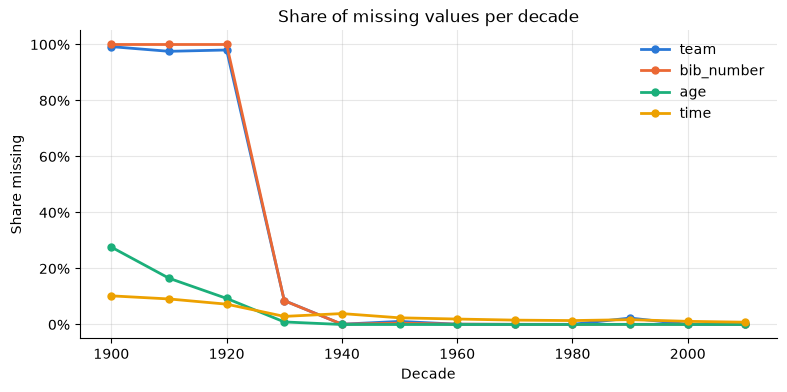

,team,bib_number,age,time
decade,,,,
1900,0.992,1.000,0.276,0.102
1910,0.976,1.000,0.165,0.091
1920,0.980,1.000,0.093,0.073
1930,0.085,0.085,0.009,0.029
1940,0.001,0.001,0.000,0.039
1950,0.011,0.005,0.000,0.024
1960,0.001,0.001,0.000,0.019
1970,0.001,0.001,0.000,0.016
1980,0.001,0.000,0.000,0.014


In [7]:
stage_data["decade"] = (stage_data["year"] // 10) * 10
cols = ["team", "bib_number", "age", "time"]
missing_by_decade = stage_data.groupby("decade")[cols].apply(lambda d: d.isna().mean())

fig, ax = plt.subplots()
for col, color in zip(cols, COLORS):
    ax.plot(missing_by_decade.index, missing_by_decade[col], marker="o", markersize=5,
            color=color, label=col)
ax.set_title("Share of missing values per decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Share missing")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
plt.show()

missing_by_decade.round(3)

`points` is missing for ~87% of rows by design (points are only awarded to the top finishers of a stage), so it is left out of the plot.

**Findings:**
- Missingness is **not random over time; it is an era effect.** `team` and `bib_number` are almost entirely missing before 1930 (~98–100%). This matches history: from 1930 the Tour was raced by national teams rather than trade teams, and bib numbers start being recorded.
- `age` is missing for 28% of rows in the 1900s, falling to ~0% from the 1930s.
- From the **1930s onwards the data is essentially complete**. `time` stays at 1–3% missing, and this is almost entirely the non-finishers: 5,543 of the 5,617 rows with missing `time` have a non-numeric `rank` (section 4).
- **Implication:** imputing team or age for the early decades would be inventing data. Restricting the time window is the cleaner option (decided in section 6). Note, though, that "team" meant national teams for 1930–1961, so a team effect does not mean the same thing across eras.

## 4. The `rank` column: finishers and non-finishers

In [8]:
rank_num = pd.to_numeric(stage_data["rank"], errors="coerce")
non_numeric = stage_data.loc[rank_num.isna(), "rank"].value_counts(dropna=False)
non_numeric

rank
DNF    4236
DNS     672
OTL     467
DSQ     214
DF      155
NQ        9
Name: count, dtype: int64

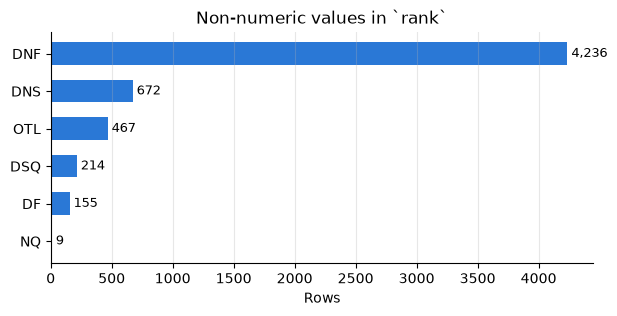

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(non_numeric.index[::-1], non_numeric.values[::-1], color=COLORS[0], height=0.6)
for y, v in enumerate(non_numeric.values[::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9)
ax.set_title("Non-numeric values in `rank`")
ax.set_xlabel("Rows")
ax.grid(axis="y", visible=False)
plt.show()

About 2% of rows (5,753) are not a finishing position. The usual meaning of each code:

| Code | Meaning | Relevant to Task B? |
|---|---|---|
| `DNF` | Did not finish the stage | **Yes**, the core abandonment event |
| `DNS` | Did not start the stage (abandoned overnight) | **Yes**, also an abandonment, just timed differently |
| `OTL` | Outside time limit (finished too slowly and was eliminated) | Arguably: an exit from the race, but not a voluntary one |
| `DSQ` | Disqualified | No: an exit for a different reason (doping, rule breaking) |
| `DF`, `NQ` | Not documented in the dataset; need checking against a few concrete rows | Unknown |

**Findings:**
- Task B has a usable signal: thousands of abandonment events, recorded at stage level.
- But "abandonment" has to be **defined**, not just read off a column. The narrowest definition is `DNF` only. A broader one is `DNF + DNS (+ OTL)`. This is a modelling decision, and it should be justified in the report.
- `DSQ` should probably be excluded from the event definition, or treated as censoring, because it is not a performance or fatigue outcome.

## 5. The time columns: is a time-gap target possible?

The proposal's preferred Task A target is the **time gap to the stage winner**. Before committing to it, we check what `time` and `elapsed` actually contain.

In [10]:
stage_data[["time", "elapsed"]].sample(10, random_state=0)

,time,elapsed
236469,49S,12S
255543,14S,7S
98584,0S,28S
151120,31S,34S
89994,22S,9S
248948,15S,47S
83229,41S,48S
45625,44S,8S
191759,53S,50S
144399,34S,34S


In [11]:
# What patterns do the values follow? Replace digits by '#' and count the distinct shapes.
for col in ["time", "elapsed"]:
    print(col, stage_data[col].str.replace(r"\d+", "#", regex=True).value_counts().to_dict())

time

 {'#S': 250135}
elapsed {'#S': 250135}


Every value has the shape `<number>S`. There are no hours or minutes, for stages that take 4–6 hours. Let's look at the range of the numbers:

In [12]:
stage_data["time_s"] = pd.to_numeric(stage_data["time"].str.rstrip("S"), errors="coerce")
stage_data["elapsed_s"] = pd.to_numeric(stage_data["elapsed"].str.rstrip("S"), errors="coerce")
stage_data[["time_s", "elapsed_s"]].describe().round(1)

,time_s,elapsed_s
count,250135.0,250135.0
mean,23.2,29.0
std,19.3,17.7
min,0.0,0.0
25%,4.0,14.0
50%,21.0,29.0
75%,40.0,44.0
max,59.0,59.0


Both columns only take values **0–59**. That strongly suggests that only the *seconds component* of a duration survived. A plausible cause: the times were stored as R duration objects (`Hh Mm Ss`) and only the seconds part was kept when exported to CSV.

To test this, we look at a stage whose real result is known: the opening **individual time trial of 2017** (Düsseldorf, 14 km). Geraint Thomas won it in 16:04, with Stefan Küng 5 seconds behind.

In [13]:
itt_2017 = stage_data.query("year == 2017 and stage_results_id == 'stage-1'")
itt_2017[["rank", "rider", "time", "elapsed"]].head(6)

,rank,rider,time,elapsed
244996,1,Thomas Geraint,4S,4S
244997,2,Küng Stefan,5S,9S
244998,3,Kiryienka Vasil,7S,11S
244999,4,Martin Tony,8S,12S
245000,5,Trentin Matteo,10S,14S
245001,6,Froome Chris,12S,16S


This fits exactly:

- **Thomas (winner):** `time = 4S`, `elapsed = 4S`, i.e. the seconds part of **16:0<u>4</u>**.
- **Küng:** `time = 5S` (his gap was +5 s) and `elapsed = 9S`, i.e. the seconds part of 16:0<u>9</u> = 16:04 + 0:05.

So the hypothesis is:

- `time` = **gap to the stage winner, modulo 60 s** (for the winner, his own time modulo 60)
- `elapsed` = **total stage time, modulo 60 s**

If this is right, then for every non-winner, `(winner's elapsed + gap) mod 60` should equal their `elapsed`. We can test that on the whole dataset, not just one stage:

In [14]:
stage_data["rank_num"] = pd.to_numeric(stage_data["rank"], errors="coerce")
key = ["year", "stage_results_id"]

winner_elapsed = (stage_data[stage_data["rank_num"] == 1]
                  .groupby(key)["elapsed_s"].first().rename("winner_elapsed_s"))
check = stage_data.join(winner_elapsed, on=key)
check = check[(check["rank_num"] > 1) & check["time_s"].notna()]

holds = (check["winner_elapsed_s"] + check["time_s"]) % 60 == check["elapsed_s"]
print(f"Hypothesis holds for {holds.mean():.1%} of {len(check):,} non-winner rows")

Hypothesis holds for 100.0% of 247,668 non-winner rows


**Findings: this is the most important result of the notebook so far.**

- The hypothesis holds for **100%** of rows. `time` and `elapsed` are the gap and the total time, with **hours and minutes lost**. A rider 3:12 behind and a rider 0:12 behind both appear as `12S`.
- The information is destroyed, not just badly formatted: it **cannot be recovered** from this file.
- **Consequence for Task A:** the time-gap target is **not usable from this CSV**. As it stands, the preferred target in the research proposal cannot be built from this data.

**Options:**

| Option | Pros | Cons |
|---|---|---|
| **A. Recover the full times** from the dataset's upstream source (the TidyTuesday data was built from an existing scraped Tour de France dataset) | Keeps the original, more informative target | Extra acquisition work, and new data-quality risks to check |
| **B. Use a rank-based target**, e.g. finishing position normalised by the number of finishers in that stage (percentile rank) | `rank` is intact, available now, and comparable across stages of different size | Discards *how far* behind a rider was: on flat stages, 150 riders share the same time but get different ranks |
| **C. Change the task**, e.g. predict a top-N finish (classification) | Simple and robust | Moves further from the proposal and loses information |

The choice between these is a project decision with consequences for every model downstream. It is logged as an open item in `PROGRESS.md` rather than settled here.

Note that `time_s` / `elapsed_s` are created only for this diagnosis. They should **never** be used as features, because they are noise.

In [15]:
# Drop the diagnostic columns so they can't leak into later analysis
stage_data = stage_data.drop(columns=["time_s", "elapsed_s"])

### 5b. Update: recovering the full times (Option A)

The TidyTuesday documentation confirms the diagnosis: `elapsed` was stored as a `lubridate::period` and written straight to CSV. The original `tdf` R package, which the TidyTuesday data was built from, ships an `.rda` file in which each Period still has its hour, minute and day components.

`src/load_data.py` reads that file directly in Python (via the `rdata` package, so no R install is needed). It writes `data/processed/stage_results.csv`, with `time_s` (gap to the winner, in seconds) and `elapsed_s` (stage time, in seconds). Run it once from the repo root: `python src/load_data.py`.

Before trusting the rebuilt file, we check it against the TidyTuesday CSV. It should contain exactly the same rows, and its times modulo 60 should equal the surviving seconds:

In [16]:
results = pd.read_csv("../data/processed/stage_results.csv", dtype={"rank": str})

same_rows = (results[["year", "stage_results_id", "rider"]].values
             == stage_data[["year", "stage_results_id", "rider"]].values).all()
old_time = pd.to_numeric(stage_data["time"].str.rstrip("S"))
has_time = results["time_s"].notna()
mod60_match = ((results.loc[has_time, "time_s"] % 60).round() == old_time[has_time]).mean()

print(f"Same rows in same order: {same_rows}")
print(f"time_s mod 60 matches the CSV's seconds: {mod60_match:.1%}")

Same rows in same order: True
time_s mod 60 matches the CSV's seconds: 100.0%


In [17]:
def hms(seconds):
    s = int(seconds)
    return f"{s // 3600}:{s % 3600 // 60:02d}:{s % 60:02d}"

# Sanity check against known results: Garin won stage 1 of 1903 in 17:45:13;
# Thomas won the 2017 opening time trial in 16:04
for year, stage in [(1903, "stage-1"), (2017, "stage-1")]:
    top = results.query("year == @year and stage_results_id == @stage").head(3)
    print(year, stage, [(r.rider, hms(r.elapsed_s), "+" + hms(r.time_s) if r.rank != "1" else "")
                        for r in top.itertuples()])

1903 stage-1 [('Garin Maurice', '17:45:13', ''), ('Pagie Émile', '17:46:08', '+0:00:55'), ('Georget Léon', '18:20:12', '+0:34:59')]
2017 stage-1 [('Thomas Geraint', '0:16:04', ''), ('Küng Stefan', '0:16:09', '+0:00:05'), ('Kiryienka Vasil', '0:16:11', '+0:00:07')]


**Findings:**
- The rebuilt file matches the TidyTuesday CSV row for row, and agrees with known historical results. **Option A is feasible, and the time-gap target is back on the table.**
- But the Task A target still has to be **chosen**, not just recovered. Raw seconds behind the winner mean very different things on a flat stage (most of the pack finishes together) and on a mountain stage (gaps of several minutes). Should the gap be normalised by stage, or by stage type?
- **Quirks to investigate before modelling:**
  - `elapsed_s` ranges from 0 h to over 150 h, so some entries are clearly errors.
  - In team time trials, the rows seem to hold *overall standings* rather than stage results. For example, the 2019 stage 2 "winner" time of 4:51:34 is Teunissen's cumulative time.

From here on, `results` (not `stage_data`) is the main table.

---
## 6. Which years to keep?

*To do.* Guiding questions:
- Combine the missingness-by-decade plot with what you know about how the race changed (team structure, field size, stage formats). Is there a natural cut-off?
- How many rider-stage rows and riders remain under each candidate cut-off (e.g. 1950, 1980, 1990)?
- Remember the `stages` table stops at 2017.

## 7. Rider history length

*To do.* Guiding questions:
- Per rider: how many stages, and how many editions?
- What does the distribution look like? A histogram, probably on a log scale.
- Are there enough riders with only 1–2 editions to test H2 (Bayesian advantage on sparse-history riders)?
- Watch out: is `rider` a reliable identifier? Check for name variants or homonyms.

## 8. Joining results to stage characteristics

Rider results (`results`) need stage characteristics (distance, type) from `stages`. There is no shared ID, so we build a key `(year, stage label)`:

- `results.stage_results_id` looks like `stage-1`, `stage-1a`, `stage-0`
- `stages.Stage` looks like `1`, `1a`, `P` (prologue)

So: strip the `stage-` prefix on one side, and map `P` to `0` on the other.

In [18]:
results["stage"] = results["stage_results_id"].str.replace("stage-", "", regex=False)
stages["year"] = stages["Date"].dt.year
stages["stage"] = stages["Stage"].astype(str).str.lower().replace({"p": "0"})

assert not stages.duplicated(["year", "stage"]).any(), "join key must be unique in stages"

result_stages = results[["year", "stage"]].drop_duplicates()
match = result_stages.merge(stages[["year", "stage"]], on=["year", "stage"],
                            how="outer", indicator=True)
match["_merge"].value_counts()

_merge
both          2198
left_only       46
right_only      38
Name: count, dtype: int64

In [19]:
only_results = match.query("_merge == 'left_only'")
print("Result stages without stage info, by year:")
print(only_results.groupby("year").size().to_dict())

only_stages = match.query("_merge == 'right_only'")
print(f"\nStages without any rider results: {len(only_stages)}, e.g. years",
      sorted(only_stages["year"].unique())[:10], "...")

Result stages without stage info, by year:
{1967: 2, 1968: 2, 2018: 21, 2019: 21}

Stages without any rider results: 38, e.g. years [np.int64(1927), np.int64(1931), np.int64(1933), np.int64(1934), np.int64(1936), np.int64(1937), np.int64(1938), np.int64(1939), np.int64(1951), np.int64(1952)] ...


**Findings:**
- The join is clean. **2,198 stages match.** Of the result stages without stage info, 42 are from 2018–2019 (the `stages` table ends in 2017). The other 4 are the 1967–68 prologues, labelled `0/1` in one table and `1a/1b` in the other. They're not worth a special case.
- 38 stages in `stages` have **no rider results** at all (mostly the extra stages of the 1930s–80s, e.g. `10c`, `23`, `24`). These are holes in the results data, not join failures.
- **Consequence:** any model that uses stage characteristics is limited to **≤ 2017**.

### 8.1 Grouping stage types

`Type` has 18 raw labels. Before grouping them, check *when* each label is used:

In [20]:
stages.groupby("Type")["year"].agg(["min", "max", "count"]).sort_values("min")

,min,max,count
Type,,,
Stage with mountain(s),1903,2003,530
Plain stage,1903,2007,1053
Stage with mountain,1919,1920,11
Team time trial,1927,2015,87
Individual time trial,1934,2017,205
Mountain time trial,1939,2016,13
Hilly stage,1972,2006,76
Flat Stage,1976,1976,9
Half Stage,1976,1976,5


The labels follow an **era-dependent taxonomy**, not just inconsistent spelling:

- Until ~2003–2007, stages are mostly `Plain stage` or `Stage with mountain(s)`, a two-way split.
- Later, organisers use `Flat` / `Hilly` / `Medium mountain` / `High mountain`.
- `Hilly stage` only appears from 1972.

So a **"hilly" category is not available consistently across eras**. Before ~1970, a hilly stage would have been labelled either "plain" or "with mountains".

The proposed grouping:

In [21]:
STAGE_TYPE_MAP = {
    # flat
    "Plain stage": "flat", "Flat stage": "flat", "Flat Stage": "flat",
    "Flat cobblestone stage": "flat", "Plain stage with cobblestones": "flat",
    "Transition stage": "flat",
    # hilly (only exists from 1972)
    "Hilly stage": "hilly", "Medium mountain stage": "hilly", "Intermediate stage": "hilly",
    # mountain
    "Stage with mountain(s)": "mountain", "Stage with mountain": "mountain",
    "Mountain stage": "mountain", "Mountain Stage": "mountain", "High mountain stage": "mountain",
    # time trials
    "Individual time trial": "itt", "Mountain time trial": "itt",
    "Team time trial": "ttt",
    # unclassifiable (5 stages, all 1976)
    "Half Stage": "other",
}
stages["stage_type"] = stages["Type"].map(STAGE_TYPE_MAP)
assert stages["stage_type"].notna().all(), "unmapped Type label"
stages["stage_type"].value_counts()

stage_type
flat        1179
mountain     635
itt          218
hilly        112
ttt           87
other          5
Name: count, dtype: int64

### 8.2 Sanity check: winner's average speed

A cheap way to catch broken rows is to compute each stage winner's average speed from `Distance` and `elapsed_s`. Real values are roughly 25–50 km/h, and they differ between stage types.

In [22]:
joined = results.merge(stages[["year", "stage", "Distance", "stage_type"]],
                       on=["year", "stage"], how="inner")

winners_per_stage = joined[joined["rank"] == "1"].copy()
with np.errstate(divide="ignore"):
    winners_per_stage["kmh"] = winners_per_stage["Distance"] / (winners_per_stage["elapsed_s"] / 3600)

winners_per_stage["kmh"] = winners_per_stage["kmh"].replace(np.inf, np.nan)  # elapsed_s == 0
winners_per_stage.groupby("stage_type")["kmh"].describe(percentiles=[0.5]).round(1)

,count,mean,std,min,50%,max
stage_type,,,,,,
flat,1160.0,37.7,24.9,2.7,36.8,694.1
hilly,111.0,40.1,3.6,26.1,40.6,46.4
itt,214.0,38.4,15.0,1.3,44.5,55.4
mountain,638.0,34.3,42.5,1.9,32.0,790.9
other,4.0,197.8,337.2,7.2,40.6,703.0
ttt,84.0,16.4,13.4,0.2,10.7,41.3


In [23]:
plausible = winners_per_stage["kmh"].between(15, 60)
print("Stages outside 15–60 km/h, by type:")
print(winners_per_stage.loc[~plausible, "stage_type"].value_counts().to_dict())
winners_per_stage.loc[~plausible & (winners_per_stage["stage_type"] != "ttt"),
                      ["year", "stage", "stage_type", "Distance", "elapsed_s", "kmh"]] \
    .sort_values("kmh").round(1).head(10)

Stages outside 15–60 km/h, by type:
{'ttt': 48, 'itt': 30, 'flat': 26, 'mountain': 6, 'other': 2}


,year,stage,stage_type,Distance,elapsed_s,kmh
89896,1970,20b,itt,8.2,23209.0,1.3
57498,1957,15b,itt,9.8,19487.0,1.8
167820,1995,16,mountain,149.0,279723.0,1.9
97783,1973,16b,itt,12.4,23030.0,1.9
100974,1974,19b,itt,12.0,17516.0,2.5
88224,1970,7b,itt,7.2,10271.0,2.5
115194,1980,7b,flat,92.0,122277.0,2.7
121413,1982,9b,flat,138.0,137401.0,3.6
73544,1964,10b,itt,21.0,19858.0,3.8
93763,1972,5b,itt,12.7,10773.0,4.2


**Findings:**
- **Team time trials have a median "speed" of ~11 km/h.** That confirms, across all TTTs and not just 2019, that their rows hold *overall race (GC) times*, not stage times. They can't be used for a stage-performance target and should be **excluded**.
- About 60 other stages give impossible speeds. Almost all are **split stages** (`a`/`b` half-days), which fail in two ways:
  - **Too fast** (e.g. 700 km/h): times and distances seem to be mixed up between the two halves.
  - **Too slow** (e.g. the 1970 stage 20b ITT, "won" in 6.4 h over 8 km): the rows hold GC times, like the TTTs.
  - The same happens on a few neutralised stages, e.g. 1995 stage 16, raced in tribute after Fabio Casartelli's death.
- **Cleaning rule (provisional):** keep stages whose winner's speed is within 15–60 km/h, and drop `ttt` and `other`. This keeps **2,049 of 2,198** stages.

### 8.3 What does the time gap look like by stage type?

This is the plot needed to choose the Task A target. Finishers only, winners excluded (their gap is 0 by definition), with the cleaning rule above applied. The data is split into two eras, because pre-1970 gaps are on a very different scale.

In [24]:
rank_num = pd.to_numeric(joined["rank"], errors="coerce")
good_stages = winners_per_stage.loc[plausible, ["year", "stage", "elapsed_s"]] \
    .rename(columns={"elapsed_s": "winner_s"})

finishers = (joined[rank_num.notna() & (rank_num > 1) & joined["time_s"].notna()]
             .merge(good_stages, on=["year", "stage"])
             .query("stage_type in ['flat', 'hilly', 'mountain', 'itt']")
             .copy())
finishers["gap_min"] = finishers["time_s"] / 60
finishers["gap_pct"] = finishers["time_s"] / finishers["winner_s"] * 100
finishers["era"] = np.where(finishers["year"] >= 1970, "1970+", "<1970")

(finishers.groupby(["era", "stage_type"])
 .agg(rows=("gap_min", "size"),
      share_same_time=("time_s", lambda x: (x == 0).mean()),
      median_gap_min=("gap_min", "median"),
      p90_gap_min=("gap_min", lambda x: x.quantile(0.9)),
      median_gap_pct=("gap_pct", "median"))
 .round(2))

rows  share_same_time  median_gap_min  p90_gap_min  median_gap_pct
era   stage_type                                                                     
1970+ flat        77090             0.38            0.25         8.72            0.10
      hilly       17513             0.07            7.28        20.93            2.66
      itt         20975             0.00            3.97        10.10            9.84
      mountain    38298             0.02           17.63        34.83            5.78
<1970 flat        48857             0.15            4.80        85.81            1.37
      itt          3316             0.10            6.58        15.22            8.27
      mountain    24594             0.06           14.67       119.27            3.70

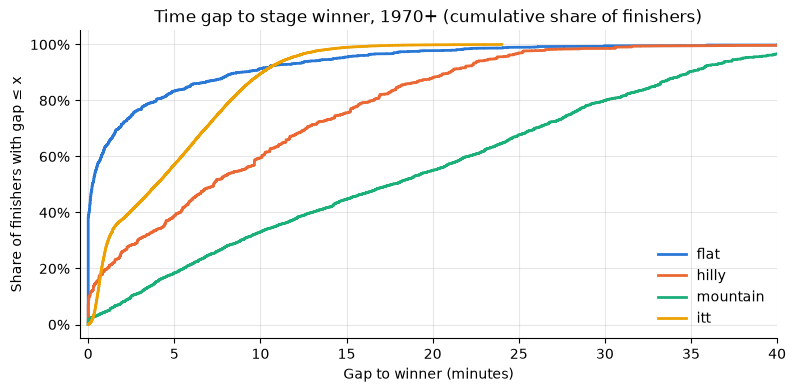

In [25]:
TYPE_ORDER = ["flat", "hilly", "mountain", "itt"]
modern = finishers[finishers["era"] == "1970+"]

fig, ax = plt.subplots()
for stage_type, color in zip(TYPE_ORDER, COLORS):
    gaps = np.sort(modern.loc[modern["stage_type"] == stage_type, "gap_min"].values)
    ecdf = np.arange(1, len(gaps) + 1) / len(gaps)
    ax.step(gaps, ecdf, where="post", color=color, label=stage_type)
ax.set_xlim(-0.5, 40)
ax.set_title("Time gap to stage winner, 1970+ (cumulative share of finishers)")
ax.set_xlabel("Gap to winner (minutes)")
ax.set_ylabel("Share of finishers with gap ≤ x")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False, loc="lower right")
plt.show()

**How to read it:** each curve shows, for one stage type, the share of finishers whose gap is at most *x* minutes. A curve that jumps up at 0 means many riders are given the same time as the winner.

**Findings (1970+):**
- **Flat stages:** 38% of finishers get *exactly the winner's time* (the bunch finish), and the median gap is 15 seconds. The distribution has a **large spike at zero** and a long tail of riders dropped later in the stage.
- **Mountain stages:** almost nobody finishes with the winner (2%). The median gap is ~18 minutes, and the 90th percentile is ~35 minutes.
- **Hilly stages** sit in between (median ~7 min). **ITTs** have no ties (median ~4 min).
- The scale differs by **~70×** between flat and mountain stages in median terms. The **spread** differs just as much, which matters for every model with a single noise term (σ).
- Dividing by the winner's time (`median_gap_pct`) doesn't fix this. It narrows the flat/mountain contrast, but makes ITTs look worst (short stages → large percentages).
- Pre-1970 gaps are much larger and noisier (p90 of 1.5–2 hours on flat/mountain stages), which supports restricting the years (section 6).

### Decision: what is the Task A target?

| Option | What it is | Main consequence |
|---|---|---|
| **1. Raw gap (seconds)** | `time_s` as is | Spike at 0 plus strongly type-dependent variance. A Normal likelihood is a poor fit; this needs a log transform, or a model in which σ depends on stage type. |
| **2. Log gap**, e.g. `log(1 + gap_s)` | Compresses the tail | Handles the scale differences, but the flat-stage zeros remain a spike. Coefficients are read as multiplicative effects. |
| **3. Gap standardised within stage** (z-score of gap within each stage) | Rider's performance *relative to that day's field* | Removes stage difficulty from the target entirely. Stage features then explain less, and the question becomes "who does well *relative to the field*". |
| **4. Percentile rank within stage** | `rank / n_finishers` | Bounded 0–1 and comparable across all stages, but **ties are lost**: the 38% "same time" on flat stages get arbitrary different ranks. |
| **5. Restrict Task A to non-flat stages** (combined with 1–3) | Drop bunch-sprint stages | Removes most of the zero spike. Arguably the stages where GC-relevant performance is decided, but it shrinks the data and narrows the claim. |

Things to weigh:
- Which option gives a target where *calibration* (the core of H2 and H3) is meaningful, and not dominated by the zero spike?
- Which is easiest to explain to a sports scientist?
- Which works with all four models? (For example, quantile XGBoost and Random Forest handle a spike at zero fine; a Normal likelihood in PyMC doesn't.)

**Chosen: option 2, log gap** (`log(1 + gap_s)`), with stage type as a feature. Section 8.4 checks whether this target behaves well enough for the models.


### 8.4 Checking the log-gap target

Three questions about the chosen target, all on 1970+ finishers (winners excluded) with the cleaning rule from 8.2:

1. **Zero spike:** how big is it, and is it small once flat stages are excluded?
2. **Spread by stage type:** is the SD of the log gap similar across stage types? If yes, a model with one constant noise term (σ) is fine. If not, σ should depend on stage type.
3. **Breakaways:** how often does the winner (alone or in a small group) arrive minutes ahead of the bunch? When that happens, every other rider's gap is inflated by the winner's margin, not by their own performance.

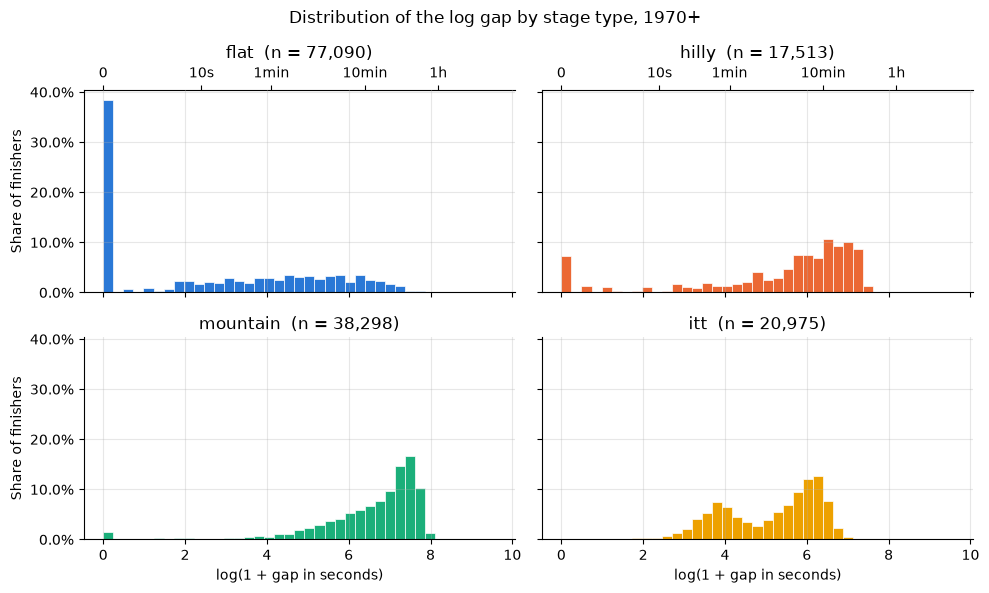

In [26]:
modern = finishers[finishers["era"] == "1970+"].copy()
modern["log_gap"] = np.log1p(modern["time_s"])

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
bins = np.linspace(0, modern["log_gap"].max(), 40)
for ax, stage_type, color in zip(axes.flat, TYPE_ORDER, COLORS):
    values = modern.loc[modern["stage_type"] == stage_type, "log_gap"]
    ax.hist(values, bins=bins, weights=np.ones(len(values)) / len(values),
            color=color, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{stage_type}  (n = {len(values):,})")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for ax in axes[1]:
    ax.set_xlabel("log(1 + gap in seconds)")
for ax in axes[:, 0]:
    ax.set_ylabel("Share of finishers")

# Secondary axis labels in real time units, so the log scale stays readable
for ax in axes[0]:
    top = ax.secondary_xaxis("top", functions=(np.expm1, np.log1p))
    top.set_xticks([0, 10, 60, 600, 3600])
    top.set_xticklabels(["0", "10s", "1min", "10min", "1h"])
fig.suptitle("Distribution of the log gap by stage type, 1970+")
fig.tight_layout()
plt.show()

In [27]:
zero_share = modern.groupby("stage_type")["time_s"].apply(lambda x: (x == 0).mean())
print("Share of finishers with gap = 0, by stage type:")
print(zero_share.round(3).to_dict())
print(f"\nAll stage types:      {(modern['time_s'] == 0).mean():.1%}")
print(f"Excluding flat stages: {(modern.loc[modern['stage_type'] != 'flat', 'time_s'] == 0).mean():.1%}")

Share of finishers with gap = 0, by stage type:
{'flat': 0.384, 'hilly': 0.074, 'itt': 0.001, 'mountain': 0.016}

All stage types:      20.5%
Excluding flat stages: 2.5%


**Findings: zero spike**
- **Yes, it's essentially a flat-stage phenomenon.** 38% of flat-stage finishers have gap = 0, against 7% on hilly stages and ≤ 2% on mountain stages and ITTs.
- Over all stage types, 20.5% of rows sit at zero. **Without flat stages, that drops to 2.5%,** which a continuous model can live with.
- The flat-stage histogram is **bimodal**: a spike at 0 (the bunch) and a second hump at minutes (riders dropped, or the bunch behind a breakaway). No single symmetric distribution describes it well.
- Two other shapes stand out:
  - **Mountain stages are left-skewed.** The log gap piles up just below ~30 min and then drops sharply. This is probably the **time limit**: dropped riders ride in together (the *gruppetto*) just fast enough to stay in the race. That's a race-tactics effect, not individual performance.
  - **ITTs are bimodal**, with humps at ~1 min and ~7 min. This is **short prologues vs long time trials**: the median gap is 0.7 min for ITTs under 15 km vs 6.2 min for longer ones. In an ITT the gap scales with distance, so stage distance should be a feature (or an interaction with stage type).

#### Spread of the log gap by stage type

Two different SDs are relevant here:
- **Overall SD per stage type** mixes two things: the differences *between* stages (some mountain stages are harder than others) and the spread of riders *within* a stage.
- **Within-stage SD** (the SD within each stage, averaged over the stages of that type) is closer to what a model's σ has to capture, once stage features and rider effects explain the rest.

In [28]:
overall_sd = modern.groupby("stage_type")["log_gap"].std()
within_sd = (modern.groupby(["stage_type", "year", "stage"])["log_gap"].std()
             .groupby("stage_type").mean())
nonzero_sd = modern[modern["time_s"] > 0].groupby("stage_type")["log_gap"].std()

sd_table = pd.DataFrame({"overall_sd": overall_sd,
                         "within_stage_sd": within_sd,
                         "overall_sd_excl_zeros": nonzero_sd}).loc[TYPE_ORDER].round(2)
sd_table

,overall_sd,within_stage_sd,overall_sd_excl_zeros
stage_type,,,
flat,2.55,1.15,1.67
hilly,2.07,1.24,1.47
mountain,1.36,0.97,1.09
itt,1.17,0.49,1.17


**Findings: spread**
- **The spread is not constant across stage types.** Overall SD ranges from ~1.2 (ITT) to ~2.5 (flat). The flat value is inflated by the bimodal zero spike: excluding the zeros, it falls to ~1.7.
- **Within-stage SD:** ITTs (~0.5) are about **half** the other types (~1.0–1.2). Riding alone against the clock produces much more consistent gaps than racing in a bunch, where riders either stay with the group or lose minutes.
- **Consequence:** a constant-σ model would be **too wide for ITTs and too narrow for flat/hilly stages**, which is exactly the kind of miscalibration H2/H3 are about. Letting **σ depend on stage type** is justified by the data. Comparing models with and without it is itself a good H2/H3 result.

#### Breakaways: how often does the winner distort everyone's gap?

Two per-stage indicators:
- **Gap of 2nd place:** if large, the winner arrived alone and clearly ahead (solo breakaway or solo attack).
- **Median finisher's gap:** if large on a *flat* stage, the bunch arrived well after the winner. A breakaway (solo or small group) stayed away, so the typical rider's gap reflects the breakaway's margin rather than their own performance.

ITTs are shown for completeness, but there is no bunch in a time trial, so a large 2nd-place gap there is simply performance.

In [29]:
per_stage = (modern.groupby(["stage_type", "year", "stage"])["time_s"]
             .agg(second_place_gap="min", median_gap="median")
             .reset_index())

breakaways = (per_stage.groupby("stage_type")
              .agg(stages=("median_gap", "size"),
                   second_place_ge_1min=("second_place_gap", lambda x: (x >= 60).mean()),
                   second_place_ge_2min=("second_place_gap", lambda x: (x >= 120).mean()),
                   median_finisher_ge_1min=("median_gap", lambda x: (x >= 60).mean()),
                   median_finisher_gap_min=("median_gap", lambda x: x.median() / 60))
              .loc[TYPE_ORDER].round(2))
breakaways

,stages,second_place_ge_1min,second_place_ge_2min,median_finisher_ge_1min,median_finisher_gap_min
stage_type,,,,,
flat,501,0.06,0.04,0.34,0.22
hilly,111,0.14,0.10,0.87,7.28
mountain,266,0.29,0.13,0.97,19.54
itt,140,0.19,0.04,0.75,5.14


**Findings: breakaways**
- **Lone winners clearly ahead** (2nd place ≥ 1 min behind): 6% of flat stages, 14% of hilly stages, 29% of mountain stages. On mountain stages, that's mostly a strong climber attacking. It's arguably real performance, not distortion.
- **The bigger effect is group breakaways on flat stages.** On **34% of flat stages**, the median finisher is ≥ 1 min behind the winner: the bunch arrived after a breakaway that stayed away. On these stages, the gap of ~150 bunch riders is set by the breakaway's margin, which says almost nothing about each rider's own performance.
- This partly explains the flat-stage bimodality above: one hump at 0 (bunch sprint), one at a few minutes (bunch behind a breakaway).

**What to do about it:**

| Option | How | Consequence |
|---|---|---|
| **a. Keep the winner as reference, add a stage-level effect** | Model a random intercept per stage (the stage's "shift") | The breakaway margin is absorbed by the stage effect, so riders are compared *within* the stage. For a *future* stage the shift is unknown, which widens predictive intervals. That is honest: nobody knows in advance whether a breakaway will succeed. |
| **b. Use the median finisher as reference** | gap = rider time − median finisher time of that stage | Removes the breakaway effect directly. But the gap can be **negative** (half the riders are ahead of the median), so `log1p` no longer works: a different transform would be needed (e.g. signed log), and the target becomes harder to explain. |
| **c. Keep as is, document it** | — | Simplest. Flat-stage predictions will carry this noise. Fine if flat stages are later dropped from Task A anyway. |

Either way, the reference choice (winner vs median finisher) should be stated explicitly in the research proposal.

### 8.5 Option b: the median finisher as reference

The idea is to measure each rider against the **median finisher of the stage** instead of the winner, so a successful breakaway no longer inflates everyone's gap:

$$\text{gap}^{med}_{i} = \text{elapsed}_i - \text{median}(\text{elapsed of all finishers in that stage})$$

Half the riders are ahead of the median, so this gap is **negative** for them, and `log1p` no longer applies. Two transforms that handle negative values:

- **Signed log:** $\text{sign}(x)\,\log(1 + |x|)$, the direct extension of the log gap.
- **Inverse hyperbolic sine:** $\text{asinh}(x / c)$. It is roughly linear for $|x| \ll c$ and logarithmic for $|x| \gg c$. The scale $c$ (in seconds) is a choice; here we try $c$ = 60 s and $c$ = 300 s.

In [30]:
# Same population as 8.3/8.4, but winners included: they're part of the median
all_finishers = (joined[rank_num.notna() & joined["elapsed_s"].notna()]
                 .merge(good_stages[["year", "stage"]], on=["year", "stage"])
                 .query("stage_type in ['flat', 'hilly', 'mountain', 'itt'] and year >= 1970")
                 .copy())
stage_median = all_finishers.groupby(["year", "stage"])["elapsed_s"].transform("median")
all_finishers["gap_med_s"] = all_finishers["elapsed_s"] - stage_median

TRANSFORMS = {
    "signed log": lambda x: np.sign(x) * np.log1p(np.abs(x)),
    "asinh(x/60)": lambda x: np.arcsinh(x / 60),
    "asinh(x/300)": lambda x: np.arcsinh(x / 300),
}
for name, fn in TRANSFORMS.items():
    all_finishers[name] = fn(all_finishers["gap_med_s"])

gm = all_finishers.groupby("stage_type")["gap_med_s"]
pd.DataFrame({
    "share_zero": gm.apply(lambda x: (x == 0).mean()),
    "share_negative": gm.apply(lambda x: (x < 0).mean()),
    "p05_min": gm.quantile(0.05) / 60,
    "p95_min": gm.quantile(0.95) / 60,
}).loc[TYPE_ORDER].round(2)

,share_zero,share_negative,p05_min,p95_min
stage_type,,,,
flat,0.72,0.11,-1.26,4.92
hilly,0.33,0.33,-10.00,12.14
mountain,0.18,0.42,-22.48,12.18
itt,0.02,0.49,-3.94,3.39


In [31]:
print(f"Share of rows exactly at the median, all types: {(all_finishers['gap_med_s'] == 0).mean():.1%}"
      f"  (vs {(modern['time_s'] == 0).mean():.1%} with the winner as reference)")

Share of rows exactly at the median, all types: 44.4%  (vs 20.5% with the winner as reference)


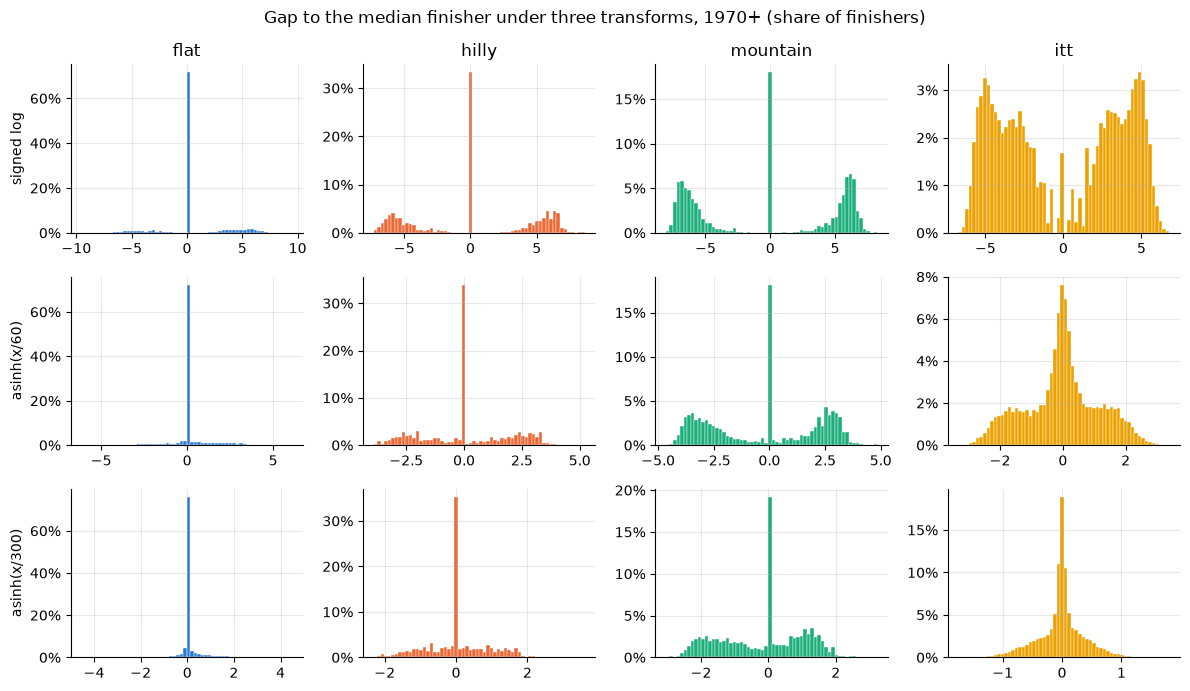

In [32]:
fig, axes = plt.subplots(len(TRANSFORMS), 4, figsize=(12, 7))
for row, name in enumerate(TRANSFORMS):
    for col, (stage_type, color) in enumerate(zip(TYPE_ORDER, COLORS)):
        ax = axes[row, col]
        values = all_finishers.loc[all_finishers["stage_type"] == stage_type, name]
        ax.hist(values, bins=60, weights=np.ones(len(values)) / len(values),
                color=color, edgecolor="white", linewidth=0.3)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        if row == 0:
            ax.set_title(stage_type)
        if col == 0:
            ax.set_ylabel(name)
fig.suptitle("Gap to the median finisher under three transforms, 1970+ (share of finishers)")
fig.tight_layout()
plt.show()

**Findings: the median reference creates more problems than it solves**

- **The zero spike gets much bigger, not smaller.** On flat stages, the median finisher is almost always *in the bunch*, so the whole bunch gets gap = 0 whether or not a breakaway got away. That's 72% of flat-stage finishers, against 38% with the winner as reference. Over all stage types, 44% of rows sit exactly at 0 (was 20.5%).
- **Hilly and mountain stages become bimodal under every transform.** The median rider typically sits in a large group of dropped riders (18% of mountain finishers share the median's exact time). Faster riders are minutes *below* it, slower riders minutes *above*, with few riders in between, so a hole opens around 0.
  - The signed log makes the hole worst, because it stretches the 1–60 s range (where almost nobody is) over 0–4 units.
  - `asinh` with a larger $c$ hides the hole only by compressing everything into a narrow band. The two groups remain.
- **The transform choice is secondary.** These shapes come from the *reference*, not the transform. The median of a race that splits into groups usually lands inside a group, not between them.
- What option b does achieve: the breakaway's margin no longer affects the bunch. But the same is achieved by the winner reference plus a per-stage effect (option a), without these side effects.

**Decision:** option b is rejected. The gap stays referenced to the winner, and breakaway effects are handled by a **per-stage random effect** (option a).

---
## Summary of decisions and open items

*(Fill in as sections are completed, and copy decisions into `PROGRESS.md`.)*

- **Data source:** `tdf` package via `src/load_data.py` (TidyTuesday `time`/`elapsed` were corrupted, section 5).
- **Join:** `(year, stage label)`, clean for ≤ 2017. **Modelling with stage features is limited to 1903–2017.**
- **Stage types:** grouped into flat / hilly / mountain / itt / ttt / other. "Hilly" only exists from 1972.
- **Cleaning (provisional):** drop `ttt` (rows are GC times) and `other`; drop stages with an implausible winner speed (outside 15–60 km/h). 2,049 of 2,198 stages kept.
- **Task A target:** **log gap**, `log(1 + time_s)`, on all stage types except `ttt`/`other`, with stage type as a feature. Known weak spot: the flat-stage zero spike (38% of finishers since 1970; only 2.5% of rows once flat stages are excluded), which must be checked in the residuals and posterior predictive checks.
- **Task B event definition:** **open** (DNF only vs DNF + DNS (+ OTL); DSQ excluded).
- **Year range:** *to decide in section 6* (section 8.3 shows pre-1970 gaps are on a different scale).
- **Noise by stage type:** within-stage SD of the log gap is ~0.5 for ITTs vs ~1.0–1.2 for other types (section 8.4). **σ should depend on stage type**; comparing constant vs stage-type σ is a candidate H2/H3 result.
- **Breakaways:** on 34% of flat stages the bunch finishes ≥ 1 min behind the winner. Reference for the gap: option b (median finisher + signed transform) was tested in section 8.5. It enlarges the zero spike (44% of rows) and makes hilly/mountain stages bimodal under every transform. **Decision: option a**, the winner as reference plus a per-stage random effect in the models. Stated in the research proposal.
